In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [25]:
DATA_PATH = "../data/raw/open_DC_motor-processing data.xlsx"

df = pd.read_excel(DATA_PATH)
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (377, 50)


In [26]:
df.head()

,File,Date,speed_rpm,speed_Hz,Current,Voltage,temp_mot,temp_amb,1x[Vibration],2x[Vibration],3x[Vibration],4x[Vibration],5x[Vibration],6x[Vibration],7x[Vibration],8x[Vibration],9x[Vibration],10x[Vibration],1x[Current],2x[Current],3x[Current],4x[Current],5x[Current],6x[Current],7x[Current],8x[Current],9x[Current],10x[Current],1x[Voltage],2x[Voltage],3x[Voltage],4x[Voltage],5x[Voltage],6x[Voltage],7x[Voltage],8x[Voltage],9x[Voltage],10x[Voltage],0-4k_Hz[Vibration],4k-8k_Hz[Vibration],8k-16kHz[Vibration],16k-26kHz[Vibration],0-4k_Hz[Current],4k-8k_Hz[Current],8k-16kHz[Current],16k-26kHz[Current],0-4k_Hz[Voltage],4k-8k_Hz[Voltage],8k-16kHz[Voltage],16k-26kHz[Voltage]
0,MOTOR-DC_2020_12_02_17_25_04_Analogico.hdf5,"02/12/2020 17:25:03,604",7919.375470,131.989591,1.609338,2.968187,26.093293,21.739496,0.130761,0.063540,0.025620,0.094017,0.377257,0.283148,0.527924,0.275906,0.512332,0.537914,0.012903,0.018567,0.011637,0.018348,0.017035,0.421847,0.017711,0.019958,0.038373,0.025739,0.003575,0.002904,0.003451,0.003913,0.003343,0.003266,0.003218,0.003333,0.003449,0.003466,11.574512,10.251101,34.332172,19.113459,4.087496,3.148589,5.021231,5.082819,1.878607,1.839876,3.634174,4.343698
1,MOTOR-DC_2020_12_02_17_25_08_Analogico.hdf5,"02/12/2020 17:25:07,815",7968.161802,132.802697,1.784386,2.951127,26.035966,21.755127,0.129288,0.065533,0.029841,0.101551,0.325202,0.267730,0.607380,0.304155,0.529731,0.378961,0.016483,0.015742,0.019662,0.021716,0.012750,0.387692,0.014537,0.019687,0.039567,0.023676,0.004162,0.003980,0.004840,0.003721,0.004128,0.004979,0.003579,0.004640,0.004281,0.004136,10.658033,9.224476,29.914340,17.828449,3.837930,2.972374,4.929544,5.110133,1.850483,1.820347,3.600817,4.306598
2,MOTOR-DC_2020_12_02_17_25_12_Analogico.hdf5,"02/12/2020 17:25:12,211",7979.458729,132.990979,1.606156,2.966607,25.968306,21.738585,0.076860,0.069520,0.052936,0.105287,0.507781,0.272668,0.751628,0.345254,0.481192,0.259373,0.015273,0.013360,0.023098,0.019530,0.017332,0.386500,0.010073,0.016263,0.035771,0.020800,0.007623,0.006717,0.008034,0.007055,0.007496,0.007704,0.007052,0.008055,0.008949,0.007958,10.626409,8.820118,29.130281,15.828031,3.838140,2.927193,4.869216,5.119583,1.945781,1.923535,3.799816,4.528593
3,MOTOR-DC_2020_12_02_17_25_17_Analogico.hdf5,"02/12/2020 17:25:16,610",7964.340995,132.739017,1.793934,2.954286,25.977693,21.763899,0.070569,0.054715,0.048879,0.087824,0.464498,0.289855,0.880029,0.428354,0.601174,0.186761,0.020930,0.022459,0.015649,0.025615,0.020325,0.367940,0.014939,0.015957,0.039438,0.019990,0.008874,0.006538,0.005333,0.006213,0.006786,0.007091,0.007252,0.007210,0.008539,0.007035,12.149690,10.087194,31.348064,18.398607,4.422911,3.360474,5.554649,5.951284,1.946259,1.907213,3.773093,4.499607
4,MOTOR-DC_2020_12_02_17_25_21_Analogico.hdf5,"02/12/2020 17:25:21,015",7979.410686,132.990178,1.720732,2.953338,26.005912,21.763027,0.122334,0.085772,0.067268,0.057775,0.496074,0.285855,0.647718,0.290123,0.515800,0.099972,0.036665,0.038009,0.027579,0.030457,0.028035,0.376220,0.022417,0.014435,0.043794,0.029029,0.005023,0.004202,0.006635,0.005032,0.004821,0.006213,0.003605,0.004349,0.016891,0.004831,10.030826,8.562675,25.925274,16.025468,4.542497,3.367668,5.913092,6.559495,2.024858,1.986529,3.925885,4.736751


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 377 entries, 0 to 376
Data columns (total 50 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   File                  377 non-null    object 
 1   Date                  377 non-null    object 
 2   speed_rpm             377 non-null    float64
 3   speed_Hz              377 non-null    float64
 4   Current               377 non-null    float64
 5   Voltage               377 non-null    float64
 6   temp_mot              377 non-null    float64
 7   temp_amb              377 non-null    float64
 8   1x[Vibration]         377 non-null    float64
 9   2x[Vibration]         377 non-null    float64
 10  3x[Vibration]         377 non-null    float64
 11  4x[Vibration]         377 non-null    float64
 12  5x[Vibration]         377 non-null    float64
 13  6x[Vibration]         377 non-null    float64
 14  7x[Vibration]         377 non-null    float64
 15  8x[Vibration]         3

In [28]:
df.shape

(377, 50)

In [29]:
for i, column in enumerate(df.columns,start=1):
    print(i,"->",column)

1 -> File
2 -> Date
3 -> speed_rpm
4 -> speed_Hz
5 -> Current
6 -> Voltage
7 -> temp_mot
8 -> temp_amb
9 -> 1x[Vibration]
10 -> 2x[Vibration]
11 -> 3x[Vibration]
12 -> 4x[Vibration]
13 -> 5x[Vibration]
14 -> 6x[Vibration]
15 -> 7x[Vibration]
16 -> 8x[Vibration]
17 -> 9x[Vibration]
18 -> 10x[Vibration]
19 -> 1x[Current]
20 -> 2x[Current]
21 -> 3x[Current]
22 -> 4x[Current]
23 -> 5x[Current]
24 -> 6x[Current]
25 -> 7x[Current]
26 -> 8x[Current]
27 -> 9x[Current]
28 -> 10x[Current]
29 -> 1x[Voltage]
30 -> 2x[Voltage]
31 -> 3x[Voltage]
32 -> 4x[Voltage]
33 -> 5x[Voltage]
34 -> 6x[Voltage]
35 -> 7x[Voltage]
36 -> 8x[Voltage]
37 -> 9x[Voltage]
38 -> 10x[Voltage]
39 -> 0-4k_Hz[Vibration]
40 -> 4k-8k_Hz[Vibration]
41 -> 8k-16kHz[Vibration]
42 -> 16k-26kHz[Vibration]
43 -> 0-4k_Hz[Current]
44 -> 4k-8k_Hz[Current]
45 -> 8k-16kHz[Current]
46 -> 16k-26kHz[Current]
47 -> 0-4k_Hz[Voltage]
48 -> 4k-8k_Hz[Voltage]
49 -> 8k-16kHz[Voltage]
50 -> 16k-26kHz[Voltage]


In [30]:
df.isnull().sum()

File                    0
Date                    0
speed_rpm               0
speed_Hz                0
Current                 0
Voltage                 0
temp_mot                0
temp_amb                0
1x[Vibration]           0
2x[Vibration]           0
3x[Vibration]           0
4x[Vibration]           0
5x[Vibration]           0
6x[Vibration]           0
7x[Vibration]           0
8x[Vibration]           0
9x[Vibration]           0
10x[Vibration]          0
1x[Current]             0
2x[Current]             0
3x[Current]             0
4x[Current]             0
5x[Current]             0
6x[Current]             0
7x[Current]             0
8x[Current]             0
9x[Current]             0
10x[Current]            0
1x[Voltage]             0
2x[Voltage]             0
3x[Voltage]             0
4x[Voltage]             0
5x[Voltage]             0
6x[Voltage]             0
7x[Voltage]             0
8x[Voltage]             0
9x[Voltage]             0
10x[Voltage]            0
0-4k_Hz[Vibr

In [31]:
df.dtypes.value_counts()

float64    48
object      2
Name: count, dtype: int64

### Statistics

In [32]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
speed_rpm,377.0,8780.042676,1018.365344,6198.087563,7887.780742,7979.458729,9726.022521,13041.030144
speed_Hz,377.0,146.334045,16.972756,103.301459,131.463012,132.990979,162.100375,217.350502
Current,377.0,2.010838,0.615758,-0.185699,1.587059,1.819396,2.605520,3.235693
Voltage,377.0,3.824467,0.998498,0.002189,2.960605,3.002624,4.855267,5.616354
temp_mot,377.0,44.700728,12.681593,25.968306,36.202379,38.244328,57.144022,71.510610
temp_amb,377.0,21.974215,0.187034,21.646436,21.838138,21.958386,22.139274,22.314419
1x[Vibration],377.0,3.020356,4.493068,0.006508,0.157084,0.252103,4.012879,25.676074
2x[Vibration],377.0,2.750300,4.657214,0.003167,0.080064,0.112391,3.904466,23.862066
3x[Vibration],377.0,2.667375,3.468609,0.002203,0.124219,0.237697,4.536497,18.398581
4x[Vibration],377.0,2.725363,3.870894,0.002240,0.062380,0.136700,3.994139,17.677254


In [33]:
main_features = [
    "speed_rpm",
    "speed_Hz",
    "Current",
    "Voltage",
    "temp_mot",
    "temp_amb"
]

df[main_features].describe().T

,count,mean,std,min,25%,50%,75%,max
speed_rpm,377.0,8780.042676,1018.365344,6198.087563,7887.780742,7979.458729,9726.022521,13041.030144
speed_Hz,377.0,146.334045,16.972756,103.301459,131.463012,132.990979,162.100375,217.350502
Current,377.0,2.010838,0.615758,-0.185699,1.587059,1.819396,2.605520,3.235693
Voltage,377.0,3.824467,0.998498,0.002189,2.960605,3.002624,4.855267,5.616354
temp_mot,377.0,44.700728,12.681593,25.968306,36.202379,38.244328,57.144022,71.510610
temp_amb,377.0,21.974215,0.187034,21.646436,21.838138,21.958386,22.139274,22.314419


In [34]:
rpm_difference = (
    df["speed_Hz"]
    -
    df["speed_rpm"] / 60
)

print(
    "Maximum RPM/Hz consistency error:",
    rpm_difference.abs().max()
)

Maximum RPM/Hz consistency error: 4.999999987376214e-07


### Correlation

In [35]:
correlation_features = [
    "speed_rpm",
    "Current",
    "Voltage",
    "temp_mot",
    "temp_amb"
]
correlation_matrix = (
    df[correlation_features]
    .corr()
)
correlation_matrix

,speed_rpm,Current,Voltage,temp_mot,temp_amb
speed_rpm,1.000000,0.719046,0.839072,0.637482,0.610668
Current,0.719046,1.000000,0.800542,0.563290,0.465084
Voltage,0.839072,0.800542,1.000000,0.707284,0.596586
temp_mot,0.637482,0.563290,0.707284,1.000000,0.698547
temp_amb,0.610668,0.465084,0.596586,0.698547,1.000000


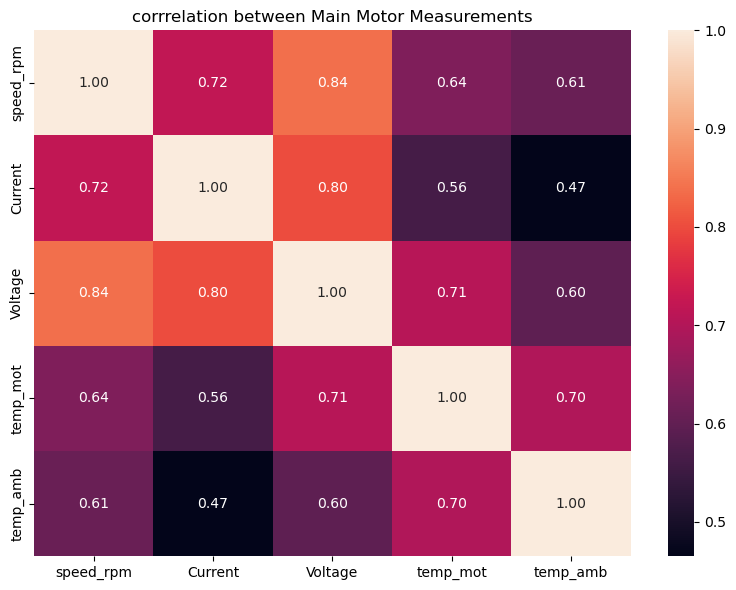

In [36]:
plt.figure(figsize = (8,6))

sns.heatmap(correlation_matrix,annot=True,fmt=".2f")
plt.title("corrrelation between Main Motor Measurements")
plt.tight_layout()
plt.show()

### Time Behavior

In [37]:
df['Date'] = pd.to_datetime(
    df['Date'],dayfirst = True
)
df = df.sort_values("Date")

C:\Users\Sahar Elgebaly\AppData\Local\Temp\ipykernel_16524\2448771986.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(


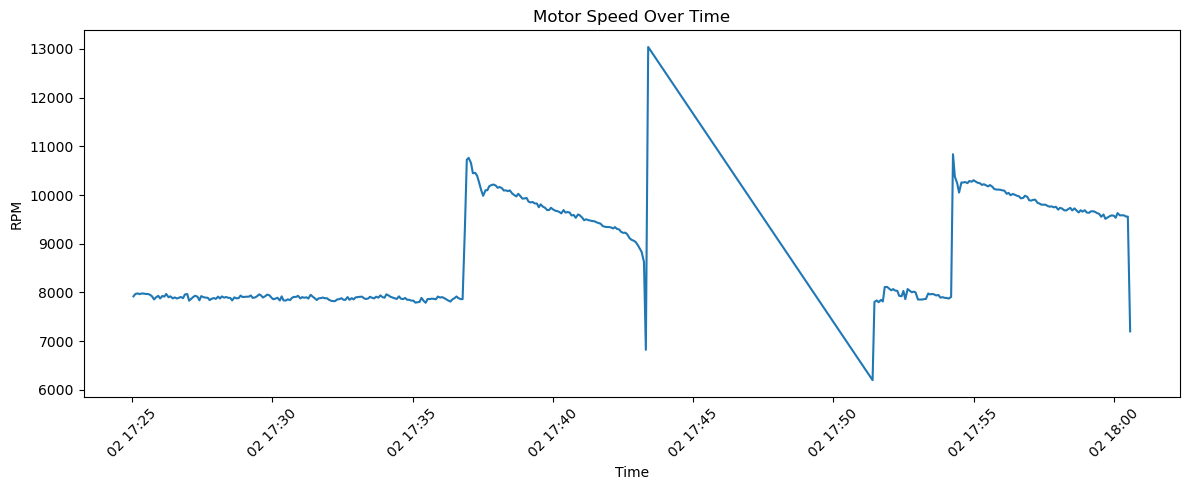

In [38]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["speed_rpm"]
)

plt.title("Motor Speed Over Time")

plt.xlabel("Time")
plt.ylabel("RPM")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

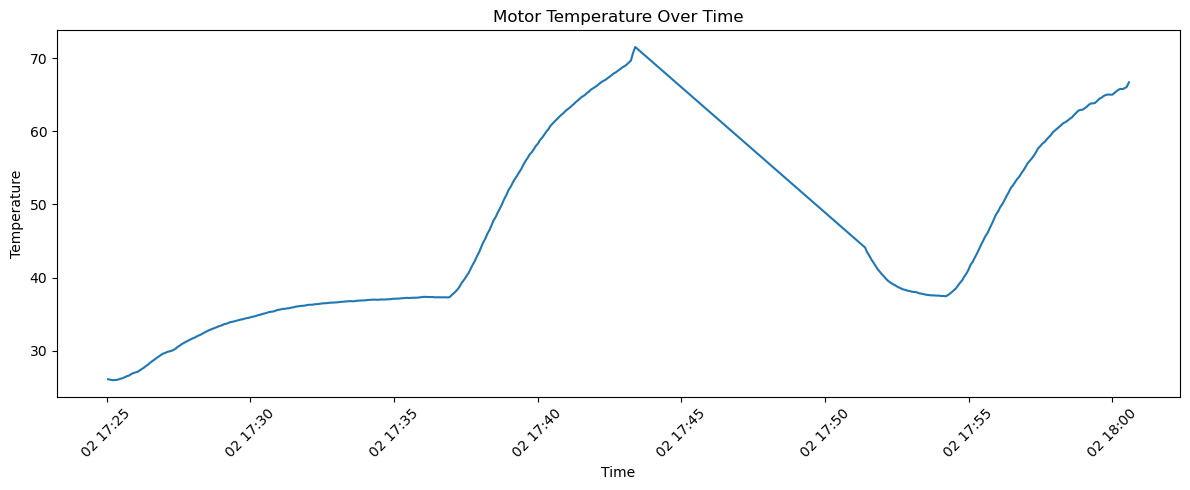

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["temp_mot"]
)

plt.title("Motor Temperature Over Time")

plt.xlabel("Time")
plt.ylabel("Temperature")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Vibration Features

In [40]:
vibration_columns = [
    column
    for column in df.columns
    if "[Vibration]" in column
]

print(
    "Vibration features:"
)

print(vibration_columns)

Vibration features:
['1x[Vibration]', '2x[Vibration]', '3x[Vibration]', '4x[Vibration]', '5x[Vibration]', '6x[Vibration]', '7x[Vibration]', '8x[Vibration]', '9x[Vibration]', '10x[Vibration]', '0-4k_Hz[Vibration]', '4k-8k_Hz[Vibration]', '8k-16kHz[Vibration]', '16k-26kHz[Vibration]']


In [41]:
df[vibration_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
1x[Vibration],377.0,3.020356,4.493068,0.006508,0.157084,0.252103,4.012879,25.676074
2x[Vibration],377.0,2.750300,4.657214,0.003167,0.080064,0.112391,3.904466,23.862066
3x[Vibration],377.0,2.667375,3.468609,0.002203,0.124219,0.237697,4.536497,18.398581
4x[Vibration],377.0,2.725363,3.870894,0.002240,0.062380,0.136700,3.994139,17.677254
5x[Vibration],377.0,3.901462,4.736341,0.003196,0.409531,0.647546,6.411030,21.430677
6x[Vibration],377.0,2.405420,3.085687,0.006479,0.237659,0.425473,3.795872,12.778759
7x[Vibration],377.0,2.339247,2.731314,0.006083,0.477052,0.793676,3.500310,10.419702
8x[Vibration],377.0,1.953173,2.604168,0.005202,0.290123,0.515234,2.980548,12.443556
9x[Vibration],377.0,2.230888,2.644248,0.005184,0.374140,0.669818,3.411902,13.877962
10x[Vibration],377.0,2.373570,3.158094,0.005220,0.284579,0.588739,3.121090,15.503811


### Current frequency features

In [42]:
current_columns = [column for column in df.columns if "[Current]" in column]
print(current_columns)

['1x[Current]', '2x[Current]', '3x[Current]', '4x[Current]', '5x[Current]', '6x[Current]', '7x[Current]', '8x[Current]', '9x[Current]', '10x[Current]', '0-4k_Hz[Current]', '4k-8k_Hz[Current]', '8k-16kHz[Current]', '16k-26kHz[Current]']


### Voltage frequency features

In [43]:
voltage_columns = [
    column
    for column in df.columns
    if "[Voltage]" in column
]

print(voltage_columns)

['1x[Voltage]', '2x[Voltage]', '3x[Voltage]', '4x[Voltage]', '5x[Voltage]', '6x[Voltage]', '7x[Voltage]', '8x[Voltage]', '9x[Voltage]', '10x[Voltage]', '0-4k_Hz[Voltage]', '4k-8k_Hz[Voltage]', '8k-16kHz[Voltage]', '16k-26kHz[Voltage]']


In [44]:
output_path = "../data/processed/real_sensor_data.csv"

df.to_csv(
    output_path,
    index=False
)

print(
    f"Real dataset saved to: {output_path}"
)

Real dataset saved to: ../data/processed/real_sensor_data.csv


In [45]:
for col in df.columns:
    if "Current" in col or "Voltage" in col:
        print(col)

Current
Voltage
1x[Current]
2x[Current]
3x[Current]
4x[Current]
5x[Current]
6x[Current]
7x[Current]
8x[Current]
9x[Current]
10x[Current]
1x[Voltage]
2x[Voltage]
3x[Voltage]
4x[Voltage]
5x[Voltage]
6x[Voltage]
7x[Voltage]
8x[Voltage]
9x[Voltage]
10x[Voltage]
0-4k_Hz[Current]
4k-8k_Hz[Current]
8k-16kHz[Current]
16k-26kHz[Current]
0-4k_Hz[Voltage]
4k-8k_Hz[Voltage]
8k-16kHz[Voltage]
16k-26kHz[Voltage]
